In [1]:
import numpy as np, matplotlib.pyplot as plt, os
import matplotlib.gridspec as gridspec
import matplotlib.ticker as plticker
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.cm as cm

import pandas as pd
from scipy.integrate import quadrature
from sklearn.metrics import matthews_corrcoef, r2_score

from glob import glob
from tqdm import tqdm

import tools21cm as t2c

plt.rcParams['font.size'] = 20
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['xtick.top'] = True
plt.rcParams['ytick.right'] = True

2024-08-28 09:21:44.471187: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-08-28 09:21:44.885460: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-08-28 09:21:44.885594: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-08-28 09:21:44.935685: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-08-28 09:21:45.043537: I tensorflow/core/platform/cpu_feature_guar

In [2]:
from matplotlib import colors
import matplotlib.pyplot as plt
import math

class MidpointNormalize(colors.Normalize):
    """
    Created by Joe Kington.
    Normalise the colorbar so that diverging bars work there way either side from a prescribed midpoint value)
    e.g. im=ax1.imshow(array, norm=MidpointNormalize(midpoint=0.,vmin=-100, vmax=100))
    """
    # set the colormap and centre the colorbar
    def __init__(self, vmin=None, vmax=None, midpoint=None, clip=False):
        self.midpoint = midpoint
        colors.Normalize.__init__(self, vmin, vmax, clip)

    def __call__(self, value, clip=None):
        # I'm ignoring masked values and all kinds of edge cases to make a simple example...
        x, y = [self.vmin, self.midpoint, self.vmax], [0, 0.5, 1]
        return np.ma.masked_array(np.interp(value, x, y), np.isnan(value))
    
def one_over_E(z, OMm):
    return 1 / np.sqrt(OMm * (1.0 + z) ** 3 + (1 - OMm))

def multiplicative_factor(z, OMm):
    return (1/one_over_E(z, OMm)/(1 + z) * quadrature(lambda x: one_over_E(x, OMm), 0, z)[0])

def wedge_slope(k_per, z, theta=np.pi/2, buffer=1e-10):
    MF = multiplicative_factor(z=z, OMm=t2c.Omega0)
    k_wedge = np.sin(theta) * MF * k_per + buffer
    return k_wedge


def PercentContours(ax, x, y, bins=None, colour='green', style=[':', '--', '-'], perc_arr=[0.99, 0.95, 0.68], lw=3):
    if(type(bins) == int):
        hist, xedges, yedges = np.histogram2d(x, y, bins=bins)
    elif(bins == 'log'):
        x_edges = np.logspace(np.log10(np.nanmin(x)), np.log10(np.nanmax(x)), 25)
        y_edges = np.logspace(np.log10(np.nanmin(y)), np.log10(np.nanmax(y)), 25)
        hist, xedges, yedges = np.histogram2d(x, y, bins=(x_edges, y_edges))
    elif(bins == 'lin'):
        x_edges = np.linspace(np.nanmin(x), np.nanmax(x), 30)
        y_edges = np.linspace(np.nanmin(y), np.nanmax(y), 30)
        hist, xedges, yedges = np.histogram2d(x, y, bins=(x_edges, y_edges))
    elif(isinstance(bins, (list, np.array))):
        hist, xedges, yedges = np.histogram2d(x, y, bins=bins)

    sort_hist = np.sort(hist.flatten())[::-1]
    perc = (np.array(perc_arr)*np.sum(sort_hist)).astype(int)
    levels = np.zeros_like(perc)

    j = -1
    for i, val in enumerate(sort_hist):
        if(np.sum(sort_hist[:i]) >= perc[j]):
            levels[j] = val
            if(j == -len(perc)):
                break
            j -= 1
    #c = plt.contour(hist.T, extent=[xedges.min(), xedges.max(), yedges.min(), yedges.max()], levels=levels, colors=colour, linestyles=style, linewidths=lw)
    x_plot, y_plot = 0.5*(xedges[1:]+xedges[:-1]), 0.5*(yedges[1:]+yedges[:-1])
    
    c = ax.contour(x_plot, y_plot, hist.T, levels=levels, colors=colour, linestyles=style, linewidths=lw)

    c.levels = np.array(perc_arr)*100.
    ax.clabel(c, c.levels, inline=True,inline_spacing=10, fmt='%d%%', fontsize=16)

## Read the Data

In [3]:
i = 232
path_prior = '/home/mbianco/Documents/PostDoc_EPFL/output/SERENEt/serenet_paper/fiducial_model/'
path_input = '/home/mbianco/Documents/PhD_Sussex/output/ML/dataset/inputs/dataLC_128_pred_190922/'
path_output = './'

#path_pred = '/home/mbianco/Documents/PostDoc_EPFL/output/SERENEt/serenet_paper/recunet17-05T09-23-54_128slice/prediction/'
#path_pred = '/home/mbianco/Documents/PostDoc_EPFL/output/SERENEt/serenet_paper/serenet24-04T16-32-44_128slice_priorGT/prediction/'
path_pred = '/home/mbianco/Documents/PostDoc_EPFL/output/SERENEt/serenet_paper/serenet01-05T17-59-07_128slice_priorTS/prediction_binary_prior/'

# Cosmology and Astrophysical parameters
with open(path_input+'parameters/user_params.txt', 'r') as file:
    params = eval(file.read())
    dr_xy = np.linspace(0, params['BOX_LEN'], params['HII_DIM'])
with open(path_input+'parameters/cosm_params.txt', 'r') as file:
    c_params = eval(file.read())

astro_params = np.loadtxt('%sparameters/astro_params.txt' %path_input)

xHI = t2c.read_cbin('%sdata/xHI_21cm_i%d.bin' %(path_input, i))
dT = t2c.read_cbin('%sdata/dT_21cm_i%d.bin' %(path_input, i))
dT3 = t2c.read_cbin('%sdata/dT3_21cm_i%d.bin' %(path_input, i))
dT4 = t2c.read_cbin('%sdata/dT4_21cm_i%d.bin' %(path_input, i))
mask_xH = t2c.read_cbin('%sdata/xH_21cm_i%d.bin' %(path_input, i))

y_true= t2c.read_cbin('%sdata/dT2_21cm_i%d.bin' %(path_input, i))
x_input = t2c.read_cbin('%sdata/dT4pca4_21cm_i%d.bin' %(path_input, i))
x_prior = t2c.read_cbin('%spredxH_from_dT4pca4_21cm_i%d.bin' %(path_prior, i))

y_pred = t2c.read_cbin('%spreddT2_from_dT4pca4_21cm_i%d.bin' %(path_pred, i))
y_error = t2c.read_cbin('%serrordT2_from_dT4pca4_21cm_i%d.bin' %(path_pred, i))

stats_serenet_i = np.loadtxt('%sstats_i%d.txt' %(path_pred, i))
stats_segunet_i = np.loadtxt('%sstats_segunet_i%d.txt' %(path_prior, i))
redshift = np.loadtxt(path_input+'lc_redshifts.txt')

r2 = stats_serenet_i[:,1]
r_phi = stats_segunet_i[:,5]

In [4]:
central_z = 7.48 #10.08
depth_mhz = 20.

central_nu = t2c.z_to_nu(central_z)
central_dist = t2c.nu_to_cdist(central_nu)
min_freq, max_freq = central_nu-depth_mhz/2., central_nu+depth_mhz/2.
min_cdist, max_cdist = t2c.z_to_cdist(t2c.nu_to_z(max_freq)), t2c.z_to_cdist(t2c.nu_to_z(min_freq))
low_z = t2c.nu_to_z(max_freq)
high_z = t2c.nu_to_z(min_freq)
print(low_z, high_z)

7.002126528442318 8.018573996405033


## Visual example 

265


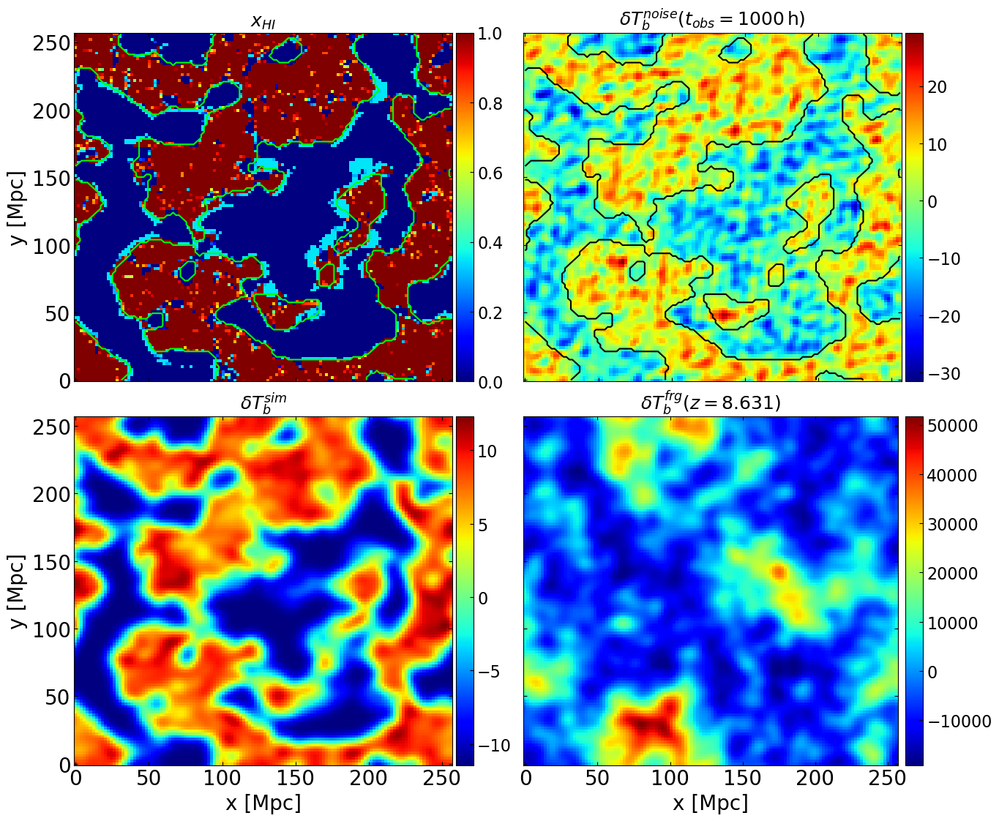

In [8]:
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['xtick.top'] = True
plt.rcParams['ytick.right'] = True

#i_slice = np.argmin(abs(np.mean(mask_xH, axis=(0,1)) - 0.5))
i_slice = np.argmin(abs(xHI.mean(axis=(0,1))  - 0.5))
print(i_slice)

nu = t2c.z_to_nu(redshift[i_slice])

fig, axs = plt.subplots(2, 2, figsize=(15, 13))
for ax in axs.flat: ax.label_outer()

plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['font.size'] = 16

axs[0,0].set_title('$x_{HI}$', size=18)
axs[0,0].contour(dr_xy, dr_xy, mask_xH[...,i_slice], colors='lime', levels=[0.5])
im = axs[0,0].pcolormesh(dr_xy, dr_xy, xHI[...,i_slice], cmap='jet')
fig.colorbar(im, ax=axs[0,0], pad=0.01, fraction=0.048)
axs[0,0].set_ylabel('y [Mpc]');

axs[0,1].set_title(r'$\delta T^{noise}_b(t_{obs}=1000\,\rm{h})$', size=18)
axs[0,1].contour(dr_xy, dr_xy, mask_xH[...,i_slice], colors='black', levels=[0.5])
im = axs[0,1].pcolormesh(dr_xy, dr_xy, dT3[...,i_slice], cmap='jet')
fig.colorbar(im, ax=axs[0,1], pad=0.01, fraction=0.048)

axs[1,0].set_title('$\delta T^{sim}_b$', size=18)
im = axs[1,0].pcolormesh(dr_xy, dr_xy, y_true[...,i_slice], cmap='jet')
axs[1,0].set_xlabel('x [Mpc]'), axs[1,0].set_ylabel('y [Mpc]');
fig.colorbar(im, ax=axs[1,0], pad=0.01, fraction=0.048)

#axs[1,1].set_title(r'$\delta T^{syn}_b(\nu=%.2f\,\rm{MHz})$' %nu, size=18)
axs[1,1].set_title(r'$\delta T^{frg}_b(z=%.3f)$' %redshift[i_slice], size=18)
im = axs[1,1].pcolormesh(dr_xy, dr_xy, dT4[...,i_slice], cmap='jet')
#axs[1,1].contour(mask_xH[...,i_slice], colors='k', levels=[0.5], extent=my_ext)
axs[1,1].set_xlabel('x [Mpc]')
fig.colorbar(im, ax=axs[1,1], pad=0.02, fraction=0.048)

plt.subplots_adjust(hspace=0.1, wspace=0.12)
#plt.savefig(path_output+'example_dataset.png', bbox_inches='tight', facecolor='white')

## Visual Prediction

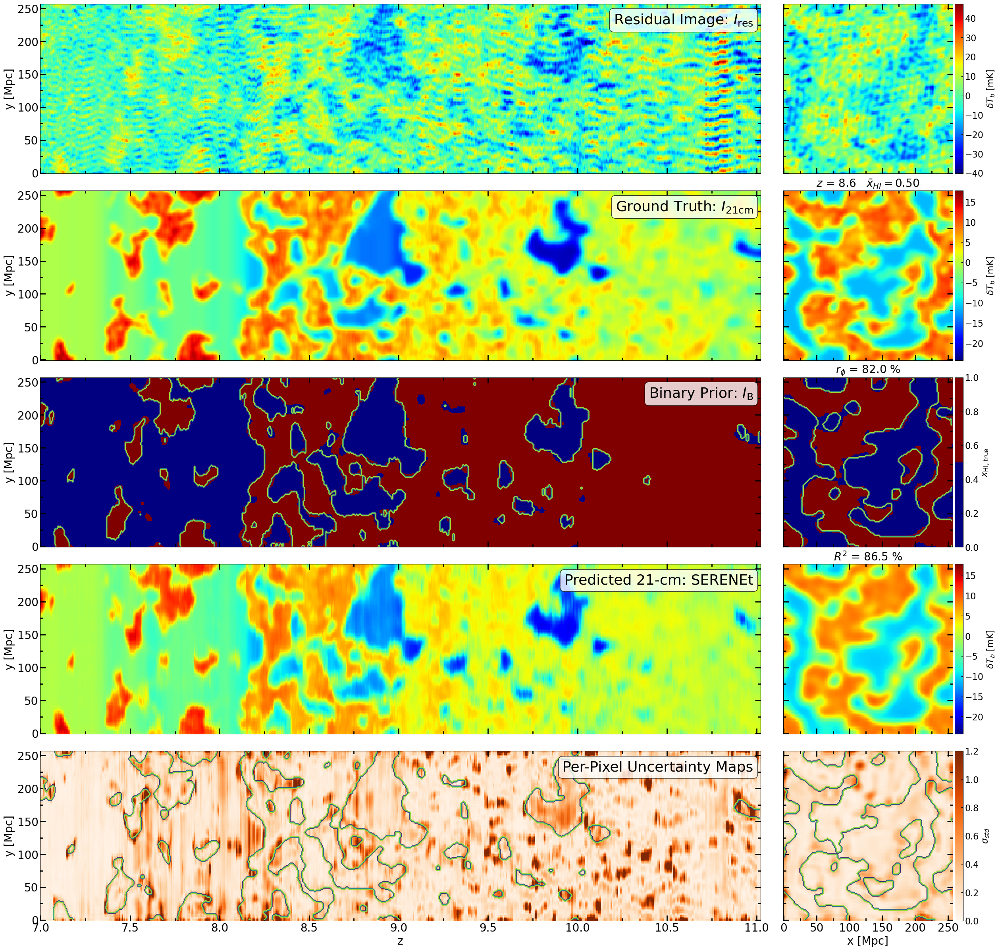

(None, None)

<Figure size 640x480 with 0 Axes>

In [5]:
box = dict(boxstyle='round', fc='white', ec='black', alpha=0.8)

# Visual Plot
i_slice = np.argmin(abs(xHI.mean(axis=(0,1)) - 0.5))
i_lc = params['HII_DIM']//2

fig = plt.figure(figsize=(30, 30), constrained_layout=True)
gs = gridspec.GridSpec(nrows=5, ncols=2, width_ratios=[4, 1], height_ratios=[1, 1, 1, 1, 1], hspace=0.1, wspace=0.05)

# FIRST LC PLOT
ax0 = fig.add_subplot(gs[0,0])
im = ax0.pcolormesh(redshift, dr_xy, x_input[:,i_lc,:], cmap='jet', vmin=x_input[0].min(), vmax=x_input[0].max())
ax0.text(0.99, 0.88, 'Residual Image: $I_\mathrm{res}$', transform=ax0.transAxes, ha='right', bbox=box, fontsize=26)
ax0.set_ylabel('y [Mpc]', size=20)

# FIRST SLICE PLOT
ax01 = fig.add_subplot(gs[0,1])
ax01.pcolormesh(dr_xy, dr_xy, x_input[...,i_slice], cmap='jet', vmin=x_input[0].min(), vmax=x_input[0].max())
fig.colorbar(im, label=r'$\delta T_b$ [mK]', ax=ax01, pad=0.01, fraction=0.048)
ax0.label_outer(), ax01.label_outer()

# SECOND LC PLOT
ax1 = fig.add_subplot(gs[1,0])
ax1.pcolormesh(redshift, dr_xy, y_true[:,i_lc,:], cmap='jet', vmin=y_true.min(), vmax=y_true.max())
ax1.text(0.99, 0.88, 'Ground Truth: $I_\mathrm{21cm}$', transform=ax1.transAxes, ha='right', bbox=box, fontsize=26)
ax1.set_ylabel('y [Mpc]', size=20)

# SECOND SLICE PLOT
ax11 = fig.add_subplot(gs[1,1])
ax11.set_title(r'$z$ = %.1f   $\bar{x}_{HI}=%.2f$' %(redshift[i_slice], xHI[...,i_slice].mean()), fontsize=20)
im = ax11.pcolormesh(dr_xy, dr_xy, y_true[...,i_slice], cmap='jet', vmin=y_true.min(), vmax=y_true.max())
fig.colorbar(im, label=r'$\delta T_b$ [mK]', ax=ax11, pad=0.01, fraction=0.048)
ax1.label_outer(), ax11.label_outer()

# THIRD LC PLOT
jet = cm.get_cmap('jet')
colors = [(0, jet(0)), (0.5, jet(0)), (0.5, jet(255)), (1, jet(255))]
custom_cmap = LinearSegmentedColormap.from_list('custom_cmap', colors)

ax2 = fig.add_subplot(gs[2,0])
ax2.pcolormesh(redshift, dr_xy, mask_xH[:,i_lc,:], cmap=custom_cmap, vmin=0, vmax=1)
ax2.contour(redshift, dr_xy, x_prior[:,i_lc,:])
ax2.text(0.99, 0.88, 'Binary Prior: $I_\mathrm{B}$', transform=ax2.transAxes, ha='right', bbox=box, fontsize=26)
ax2.set_ylabel('y [Mpc]', size=20)

# THIRD SLICE PLOT
ax21 = fig.add_subplot(gs[2,1])
ax21.set_title(r'$r_\phi$ = %.1f %%' %(100*r_phi[i_slice]), fontsize=20)
im = ax21.pcolormesh(dr_xy, dr_xy, mask_xH[...,i_slice], cmap=custom_cmap, vmin=0, vmax=1)
ax21.contour(dr_xy, dr_xy, x_prior[...,i_slice])
fig.colorbar(im, label=r'$x_\mathrm{HI,\,true}$', ax=ax21, pad=0.01, fraction=0.048)
ax2.label_outer(), ax21.label_outer()

# FOURTH LC PLOT
ax3 = fig.add_subplot(gs[3,0])
ax3.pcolormesh(redshift, dr_xy, y_pred[:,i_lc,:], cmap='jet', vmin=y_true.min(), vmax=y_true.max())
ax3.text(0.99, 0.88, 'Predicted 21-cm: SERENEt', transform=ax3.transAxes, ha='right', bbox=box, fontsize=26)
ax3.set_ylabel('y [Mpc]', size=20)

# FOURTH SLICE PLOT
ax31 = fig.add_subplot(gs[3,1])
ax31.set_title(r'$R^2$ = %.1f %%' %(100*r2[i_slice]), fontsize=20)
im = ax31.pcolormesh(dr_xy, dr_xy, y_pred[...,i_slice], cmap='jet', vmin=y_true.min(), vmax=y_true.max())
fig.colorbar(im, label=r'$\delta T_b$ [mK]', ax=ax31, pad=0.01, fraction=0.048)
ax3.label_outer(), ax31.label_outer()

# FIFTH LC PLOT
ax4 = fig.add_subplot(gs[4,0])
ax4.pcolormesh(redshift, dr_xy, y_error[:,i_lc,:], cmap='Oranges', vmin=0, vmax=1.2)
ax4.contour(redshift, dr_xy, mask_xH[:,i_lc,:], color='lime')
ax4.text(0.99, 0.88, 'Per-Pixel Uncertainty Maps', transform=ax4.transAxes, ha='right', bbox=box, fontsize=26)
ax4.set_ylabel('y [Mpc]', size=20)

# FIFTH SLICE PLOT
ax41 = fig.add_subplot(gs[4,1])
im = ax41.pcolormesh(dr_xy, dr_xy, y_error[...,i_slice], cmap='Oranges', vmin=0, vmax=1.2)
ax41.contour(dr_xy, dr_xy, mask_xH[...,i_slice], color='lime')
fig.colorbar(im, label=r'$\sigma_{std}$', ax=ax41, pad=0.01, fraction=0.048)
ax4.label_outer(), ax41.label_outer()

ax41.set_xlabel('x [Mpc]', size=20)
ax4.set_xlabel('z', size=20)

axes1 = [ax01, ax11, ax21, ax31, ax41]
axes2 = [ax0, ax1, ax2, ax3, ax4]
for axis1, axis2 in zip(axes1, axes2):
    axis1.tick_params(axis='both', which='major', length=10, width=2, labelsize=20)
    axis1.tick_params(axis='both', which='minor', length=5, width=2)
    axis2.tick_params(axis='both', which='major', length=10, width=2, labelsize=20)
    axis2.tick_params(axis='both', which='minor', length=5, width=2)
    axis1.xaxis.set_minor_locator(plticker.MultipleLocator(base=25))
    axis1.xaxis.set_major_locator(plticker.MultipleLocator(base=50))
    axis1.yaxis.set_minor_locator(plticker.MultipleLocator(base=25))
    axis2.xaxis.set_minor_locator(plticker.MultipleLocator(base=0.25))
    axis2.yaxis.set_minor_locator(plticker.MultipleLocator(base=25))

#plt.savefig('%svisual_binary_priorTS_i%d.png' %(path_output, i), bbox_inches='tight')
plt.show(), plt.clf()

## Visual Comparison between Differnet Tests at Different Redshift

In [5]:
path_fiducial = './fiducial_model/'

test1 = t2c.read_cbin(path_fiducial+'test1pred_dT4pca4_21cm_i232.bin')
test21 = t2c.read_cbin(path_fiducial+'test2.1pred_dT4pca4_21cm_i232.bin')
test32 = t2c.read_cbin(path_fiducial+'test3.2pred_dT4pca4_21cm_i232.bin') 

121 -5.5252957 14.22872
265 -11.440745 12.316368
318 -16.969282 8.532078


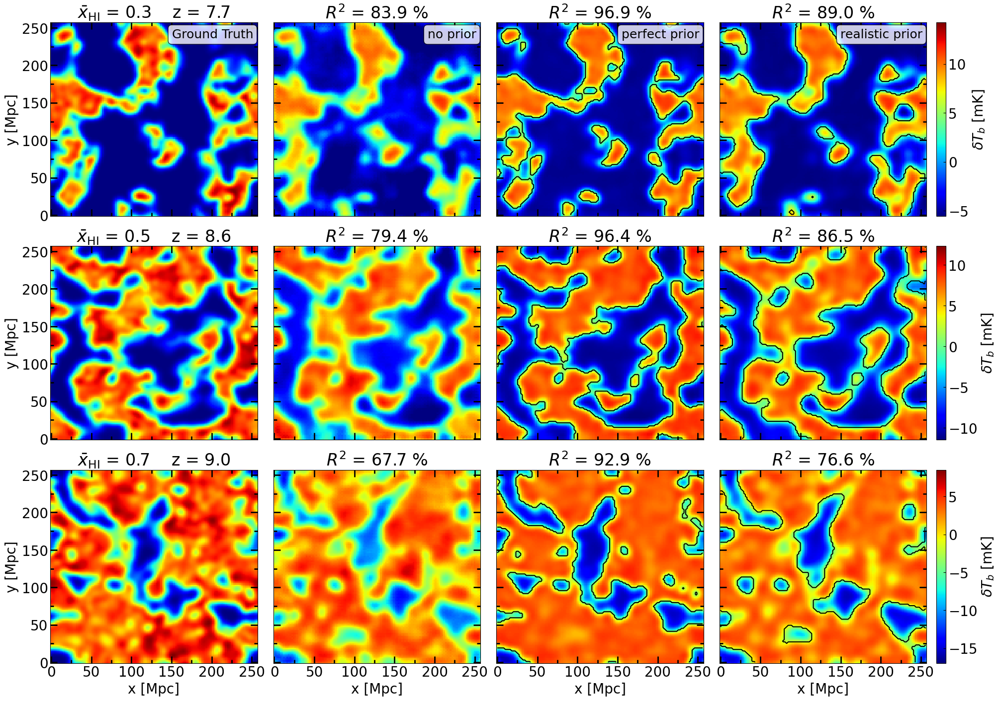

(None, None)

<Figure size 640x480 with 0 Axes>

In [7]:
text = ['Ground Truth', 'no prior', 'perfect prior', 'realistic prior']

plot_xHI = [0.3, 0.5, 0.7]
index_plot = [np.argmin(abs(xHI.mean(axis=(0,1))  - mean_xh)) for mean_xh in plot_xHI]
redshift_plot = redshift[index_plot]

fig, axs = plt.subplots(figsize=(20,14), ncols=4, nrows=redshift_plot.size, constrained_layout=True)
for i, i_plot in enumerate(index_plot):
    axs[i,0].set_title(r'$\bar{x}_{\rm HI}$ = %.1f    z = %.1f' %(plot_xHI[i], redshift_plot[i]))
    axs[i,0].pcolormesh(dr_xy, dr_xy, y_true[...,i_plot], cmap='jet', vmin=y_true[...,i_plot].min(), vmax=y_true[...,i_plot].max())
    print(i_plot, y_true[...,i_plot].min(), y_true[...,i_plot].max())
    
    axs[i,1].set_title(r'$R^2$ = %.1f %%' %(100*r2_score(y_true[...,i_plot].flatten(), test1[...,i_plot].flatten())))
    axs[i,1].pcolormesh(dr_xy, dr_xy, test1[...,i_plot], cmap='jet', vmin=y_true[...,i_plot].min(), vmax=y_true[...,i_plot].max())
    
    axs[i,2].set_title(r'$R^2$ = %.1f %%' %(100*r2_score(y_true[...,i_plot].flatten(), test21[...,i_plot].flatten())))
    axs[i,2].pcolormesh(dr_xy, dr_xy, test21[...,i_plot], cmap='jet', vmin=y_true[...,i_plot].min(), vmax=y_true[...,i_plot].max())
    axs[i,2].contour(dr_xy, dr_xy, mask_xH[...,i_plot], colors='black', levels=[0.5])

    axs[i,3].set_title(r'$R^2$ = %.1f %%' %(100*r2_score(y_true[...,i_plot].flatten(), test32[...,i_plot].flatten())))
    im = axs[i,3].pcolormesh(dr_xy, dr_xy, test32[...,i_plot], cmap='jet', vmin=y_true[...,i_plot].min(), vmax=y_true[...,i_plot].max())
    axs[i,3].contour(dr_xy, dr_xy, x_prior[...,i_plot], colors='black', levels=[0.5])
    fig.colorbar(im, label=r'$\delta T_b$ [mK]', ax=axs[i,3], pad=0.01, fraction=0.048)

    for j, ax in enumerate(axs[i,:]): 
        if(i == 0):
            box = dict(boxstyle='round', fc='white', ec='black', alpha=0.8)
            ax.text(0.98, 0.92, text[j], transform=ax.transAxes, ha='right', bbox=box, fontsize=18)

        ax.set_xlabel('x [Mpc]'), ax.set_ylabel('y [Mpc]')
        ax.label_outer()
        ax.tick_params(axis='both', which='major', length=10, width=2)
        ax.tick_params(axis='both', which='minor', length=5, width=2)
        ax.xaxis.set_minor_locator(plticker.MultipleLocator(base=25))
        ax.xaxis.set_major_locator(plticker.MultipleLocator(base=50))
        ax.yaxis.set_minor_locator(plticker.MultipleLocator(base=25))
        ax.yaxis.set_major_locator(plticker.MultipleLocator(base=50))
        
#plt.savefig('%svisual_comparison_tests.png' %path_output, bbox_inches='tight')
plt.show(), plt.clf()

## 21-cm 2D Power Spectra

-601.7993024211974 0.8425065727869602
-1823.45366671317 0.7507107859501719
-2908.4540595401095 0.8978429077975342
-398.7788342426528 0.8126894298938255
-860.6961528401582 0.736288678459734
-814.6595641013135 0.9168709311757651
-414.2421478117525 0.8463994767963916
-853.516595305065 0.8084433935962749
-464.3547152121636 0.9465291419581457


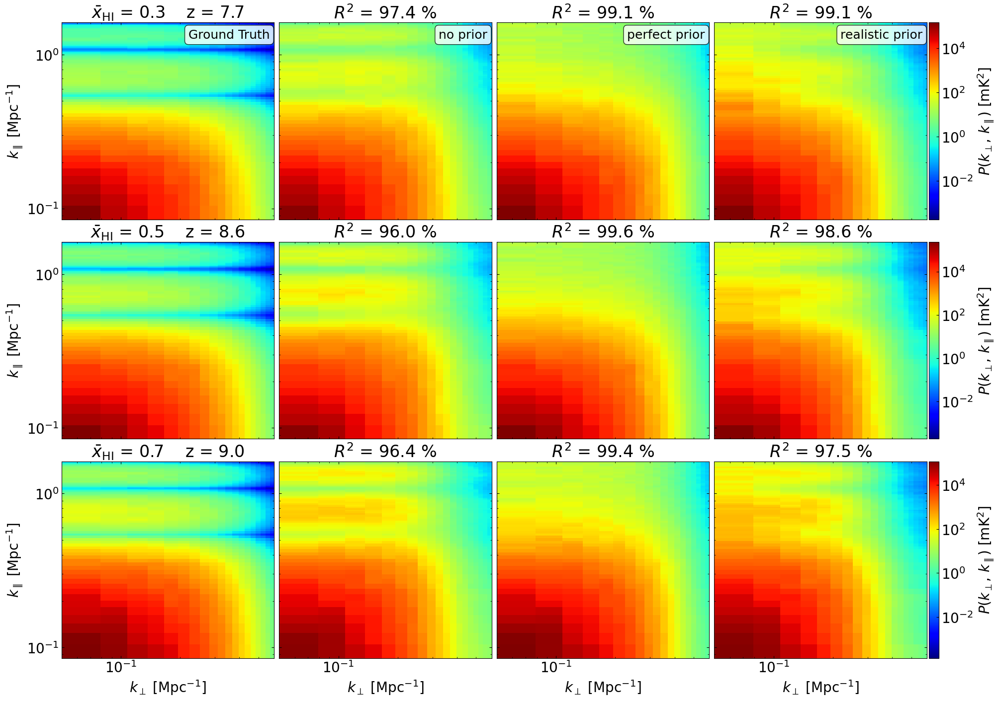

(None, None)

<Figure size 640x480 with 0 Axes>

In [8]:
from matplotlib.colors import LogNorm
import gc
box_len = 256./0.7 # cMpc
depth_mhz = 20. # MHz

# define wavelengths
#kpar_bins = np.linspace(8.5e-2, 1.62, 80)
#kper_bins = np.linspace(5e-2, 0.41, 20)
kpar_bins = np.linspace(8.5e-2, 1.62, 80)
kper_bins = np.linspace(5e-2, 0.6, 20)

kpar = 0.5*(kpar_bins[1:]+kpar_bins[:-1])
kper = 0.5*(kper_bins[1:]+kper_bins[:-1])

fig, axs = plt.subplots(figsize=(20,14), ncols=4, nrows=redshift_plot.size, constrained_layout=True)
for i, i_plot in enumerate(index_plot):
    # Ground truth
    ps_true = np.loadtxt('ps_data/ps_true_iz%d.txt' %i_plot)    
    axs[i,0].set_title(r'$\bar{x}_{\rm HI}$ = %.1f    z = %.1f' %(plot_xHI[i], redshift_plot[i]))
    axs[i,0].pcolormesh(kper, kpar, ps_true.T, cmap='jet', norm=LogNorm(vmin=ps_true.min(), vmax=ps_true.max()))

    # test 1
    ps1 = np.loadtxt('ps_data/ps_pred_test1_iz%d.txt' %i_plot)
    axs[i,1].set_title(r'$R^2$ = %.1f %%' %(100*r2_score(ps_true.flatten(), ps1.flatten())))
    axs[i,1].pcolormesh(kper, kpar, ps1.T, cmap='jet', norm=LogNorm(vmin=ps_true.min(), vmax=ps_true.max()))
    #axs[i,1].pcolormesh(kper, kpar, ps_true.T-ps1.T, cmap='bwr', vmin=-1000, vmax=1000)
    #res = 1-ps1.T/ps_true.T
    #axs[i,1].pcolormesh(kper, kpar, res, cmap='bwr', vmin=-10, vmax=1)
    print((1-ps1.T/ps_true.T).min(), (1-ps1.T/ps_true.T).max())

    # test 2.1
    ps21 = np.loadtxt('ps_data/ps_pred_test2.1_iz%d.txt' %i_plot)
    axs[i,2].set_title(r'$R^2$ = %.1f %%' %(100*r2_score(ps_true.flatten(), ps21.flatten())))
    axs[i,2].pcolormesh(kper, kpar, ps21.T, cmap='jet', norm=LogNorm(vmin=ps_true.min(), vmax=ps_true.max()))
    #axs[i,2].pcolormesh(kper, kpar, ps_true.T-ps21.T, cmap='bwr', vmin=-1000, vmax=1000)
    #res = 1-ps21.T/ps_true.T
    #axs[i,2].pcolormesh(kper, kpar, res, cmap='bwr', vmin=-10, vmax=1)
    print((1-ps21.T/ps_true.T).min(), (1-ps21.T/ps_true.T).max())

    # test 3.2
    ps32 = np.loadtxt('ps_data/ps_pred_test3.2_iz%d.txt' %i_plot)
    axs[i,3].set_title(r'$R^2$ = %.1f %%' %(100*r2_score(ps_true.flatten(), ps32.flatten())))
    im = axs[i,3].pcolormesh(kper, kpar, ps32.T, cmap='jet', norm=LogNorm(vmin=ps_true.min(), vmax=ps_true.max()))
    #im = axs[i,3].pcolormesh(kper, kpar, ps_true.T-ps32.T, cmap='bwr', vmin=-1000, vmax=1000)
    #res = 1-ps32.T/ps_true.T
    #im = axs[i,3].pcolormesh(kper, kpar, res, cmap='bwr', vmin=-10, vmax=1)
    fig.colorbar(im, label=r'$P(k_{\perp},\,k_\parallel)$ [$\rm mK^2$]', ax=axs[i,3], pad=0.01, fraction=0.048)
    print((1-ps32.T/ps_true.T).min(), (1-ps32.T/ps_true.T).max())

    for j, ax in enumerate(axs[i,:]): 
        if(i == 0):
            box = dict(boxstyle='round', fc='white', ec='black', alpha=0.8)
            ax.text(0.98, 0.92, text[j], transform=ax.transAxes, ha='right', bbox=box, fontsize=18)

        ax.set_xlabel(r'$k_{\perp}$ [$\rm Mpc^{-1}$]'), ax.set_ylabel(r'$k_{\parallel}$ [$\rm Mpc^{-1}$]')
        ax.label_outer()
        ax.set_xscale('log'), ax.set_yscale('log')

#plt.savefig('%spk_comparison_tests.png' %path_output, bbox_inches='tight')
#plt.savefig('%spk_residual_comparison_tests.png' %path_output, bbox_inches='tight')
plt.show(), plt.clf()

## Statistical analysis Random Dataset

In [34]:
path_random = '/home/mbianco/Documents/PostDoc_EPFL/output/SERENEt/serenet_paper/ps_data/larger_random_dataset/'

for i in range(0, 300):
    if(i==0):
        rnd_stats = np.loadtxt('%sytrue_pk_i%d.txt' %(path_random, i))    
    else:
        rnd_stat = np.loadtxt('%sytrue_pk_i%d.txt' %(path_random, i))    
        rnd_stats = np.vstack((rnd_stats, rnd_stat))

rnd_stats[rnd_stats<0]=0

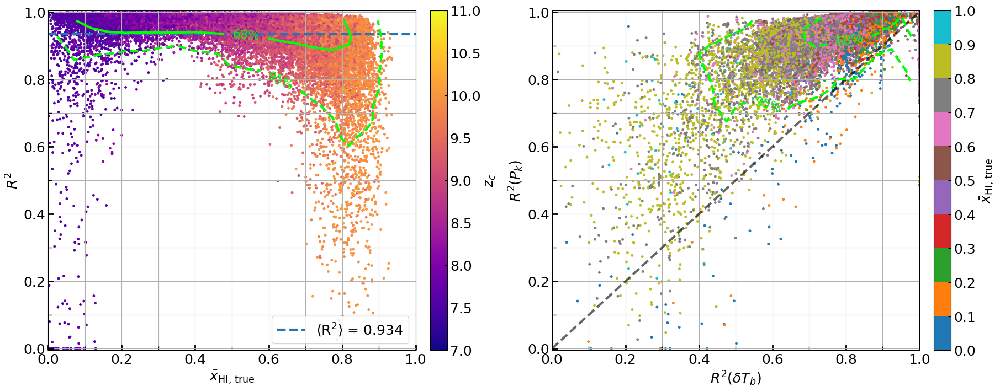

(None, None)

<Figure size 640x480 with 0 Axes>

In [36]:
from matplotlib.colors import ListedColormap, BoundaryNorm

fig1, (ax0, ax1) = plt.subplots(1, 2, figsize=(18, 7), constrained_layout=True)
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['font.size'] = 18
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.right'] = False

from scipy.stats import binned_statistic_2d
bins_xH = np.linspace(0., 1., 100)
N_r2 = binned_statistic_2d(x=rnd_stats[:,2], y=rnd_stats[:,3], values=rnd_stats[:,3], statistic='mean', bins=[bins_xH, 1]).statistic
interp_mean_r2, mid_bin_xH = N_r2.flatten(), 0.5*(bins_xH[1:]+bins_xH[:-1])

# PLOT STATS
im = ax0.scatter(rnd_stats[:,2], rnd_stats[:,3], c=rnd_stats[:,1], vmin=7, vmax=11, s=25, cmap='plasma', marker='.')
#ax0.plot(mid_bin_xH, interp_mean_r2, color='tab:blue', lw=3, ls='-', label='')
ax0.hlines(xmin=0, xmax=1, y=rnd_stats[:,3].mean(), color='tab:blue', lw=3, ls='--', label=r'$\rm \left<R^2\right>$ = %.3f' %rnd_stats[:,3].mean())
PercentContours(ax=ax0, x=rnd_stats[:,2], y=rnd_stats[:,3], bins=20, colour='lime', style=['--', '-'], perc_arr=[0.95, 0.68], lw=3)
ax0.set_xlabel(r'$\bar{x}_{\rm HI,\,true}$'), ax0.set_ylabel(r'$R^2$')
cbar = plt.colorbar(im, ax=ax0, label='$z_c$', pad=0.01)
ax0.legend(loc=4)

#im = ax1.scatter(rnd_stats[:,4], rnd_stats[:,3], c=rnd_stats[:,1], vmin=7, vmax=11, s=25, cmap='plasma', marker='.')
colors = plt.cm.tab20.colors[:10]
cmap = ListedColormap(colors)

im = ax1.scatter(rnd_stats[:,4], rnd_stats[:,3], c=rnd_stats[:,2], vmin=0, vmax=1, s=25, cmap='tab10', marker='.')
ax1.set_xlabel(r'$R^2(\delta T_b)$'), ax1.set_ylabel(r'$R^2(P_{k})$')
#ax1.label_outer()
ax1.plot(np.linspace(0,1,10), np.linspace(0,1,10), 'k--', lw=3, alpha=0.6)
PercentContours(ax=ax1, x=rnd_stats[:,4], y=rnd_stats[:,3], bins=30, colour='lime', style=['--', '-'], perc_arr=[0.68], lw=3)
PercentContours(ax=ax1, x=rnd_stats[:,4], y=rnd_stats[:,3], bins=20, colour='lime', style=['--', '-'], perc_arr=[0.95], lw=3)
cbar = plt.colorbar(im, ax=ax1, label=r'$\bar{x}_{\rm HI,\,true}$', pad=0.01)
cbar.set_ticks(np.linspace(0, 1, 11))

for ax in [ax0, ax1]:
    ax.set_ylim(-0.005, 1.005), ax.set_xlim(0.0, 1.0)
    ax.xaxis.set_major_locator(plt.MultipleLocator(0.2))
    ax.xaxis.set_minor_locator(plt.MultipleLocator(0.1))
    ax.yaxis.set_major_locator(plt.MultipleLocator(0.2))
    ax.yaxis.set_minor_locator(plt.MultipleLocator(0.1))
    ax.grid(which='both')
    ax.tick_params(axis='both', length=7, width=2)
    ax.tick_params(axis='both', which='minor', length=5, width=1)

#plt.savefig('%sstats_pk_dataset.png' %(path_output), bbox_inches='tight')
plt.subplots_adjust(hspace=0.01)
plt.show(), plt.clf()

## Statistical analysis Fiducial Dataset

In [13]:
stats_serenet_i = np.loadtxt('fiducial_model/stats_i232.txt', usecols=(0,1,2,5))

redshift = stats_serenet_i[:,0]
#r2 = stats_serenet_i[:,1:]
r2_test1, r2_test21, r2_test32 = stats_serenet_i[:,1:].T

mean_xh = xHI.mean(axis=(0,1))

In [63]:
xHI_fit = np.linspace(0.1, 0.9, 10)
p = np.poly1d(np.polyfit(redshift, mean_xh, 12))    # fit a polynomial to make the distribution smoother

redshift_plot = np.array([redshift[np.argmin(abs(p(redshift) - meanHI))] for meanHI in xHI_fit])

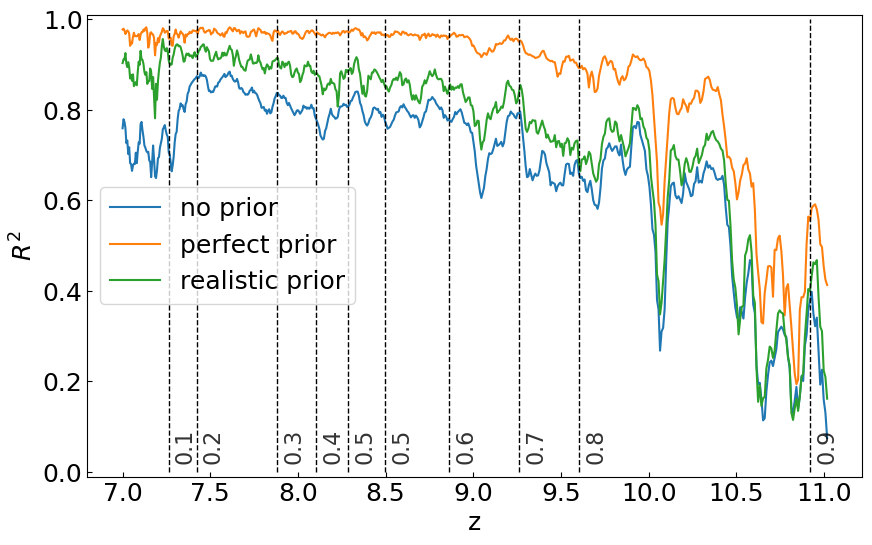

In [90]:
fig = plt.figure(figsize=(10,6))
plt.plot(redshift, r2_test1, label='no prior', color='tab:blue')
plt.plot(redshift, r2_test21, label='perfect prior', color='tab:orange')
plt.plot(redshift, r2_test32, label='realistic prior', color='tab:green')
plt.xlabel('z'), plt.ylabel(r'$R^2$')
plt.ylim(-0.01, 1.01)
plt.legend(loc=6)

plt.vlines(redshift_plot, ymin=0, ymax=1, color='black', ls='--', lw=1)
for iplot in range(redshift_plot.size):
    plt.text(redshift_plot[iplot]+0.03, 0.03, round(xHI_fit[iplot], 1), rotation=90, size=16, alpha=0.8)

#plt.savefig('%sstat_fiducial_tests.png' %path_output, bbox_inches='tight')

## Statistical analysis Random Dataset

In [5]:
path_prior = '/home/mbianco/Documents/PostDoc_EPFL/output/SERENEt/serenet_paper/segunet24-09T23-36-45_128slice_paper2/prediction/'
#path_pred = '/home/mbianco/Documents/PostDoc_EPFL/output/SERENEt/serenet_paper/recunet17-05T09-23-54_128slice/prediction/'
#path_pred = '/home/mbianco/Documents/PostDoc_EPFL/output/SERENEt/serenet_paper/serenet24-04T16-32-44_128slice_priorGT/prediction/'
path_pred = '/home/mbianco/Documents/PostDoc_EPFL/output/SERENEt/serenet_paper/serenet01-05T17-59-07_128slice_priorTS/prediction_binary_prior/'

redshift = np.loadtxt(path_input+'lc_redshifts.txt')
i_fiducial = 232

In [7]:
for i_pred in range(0, 300):
    stats_segunet_i = np.loadtxt('%sstats_i%d.txt' %(path_prior, i_pred))
    rates_segunet_i = np.loadtxt('%srates_i%d.txt' %(path_prior, i_pred))
    stats_serenet_i = np.loadtxt('%sstats_i%d.txt' %(path_pred, i_pred))
    
    if(i_pred == 0):
        r2 = stats_serenet_i[:,1]
        r_phi = rates_segunet_i[:,5]
        mean_xh = stats_segunet_i[:,-1]
        redshifts = redshift
    else:
        r2 = np.hstack((r2, stats_serenet_i[:,1]))
        r_phi =  np.hstack((r_phi, rates_segunet_i[:,5]))
        mean_xh = np.hstack((mean_xh, stats_segunet_i[:,-1]))
        redshifts = np.hstack((redshifts, redshift))
    
    if(i_pred == i_fiducial):
        r2_fiducial = stats_serenet_i[:,1]
        r_phi_fiducial = rates_segunet_i[:,5]
        mean_xh_fiducial = stats_segunet_i[:,-1]

i_sort = np.argsort(mean_xh_fiducial)
r2_fiducial = r2_fiducial[i_sort]
mean_xh_fiducial = mean_xh_fiducial[i_sort]
r_phi_fiducial = r_phi_fiducial[i_sort]

r2 = np.clip(r2, 0, 1)

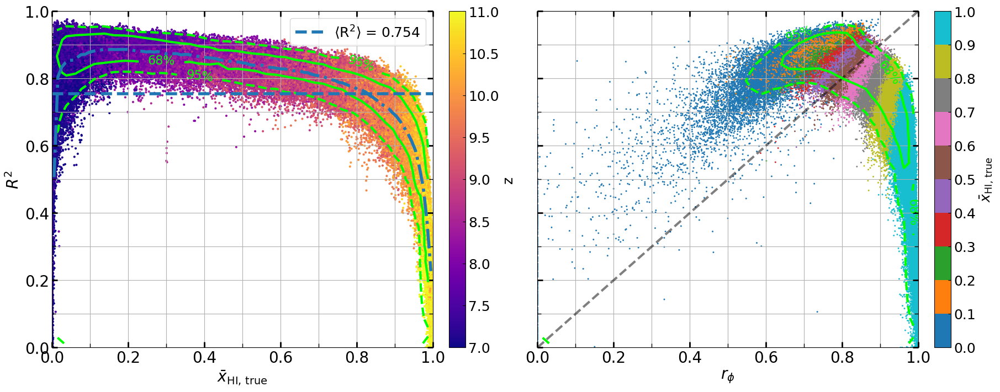

(None, None)

<Figure size 640x480 with 0 Axes>

In [8]:
fig1, (ax0, ax1) = plt.subplots(figsize=(18, 7), nrows=1, ncols=2, constrained_layout=True)
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['font.size'] = 18
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.right'] = False

from scipy.stats import binned_statistic_2d
bins_xH = np.linspace(0., 1., 100)
N_r2 = binned_statistic_2d(x=mean_xh, y=r2, values=r2, statistic='mean', bins=[bins_xH, 1]).statistic
N_stdr2 = binned_statistic_2d(x=mean_xh, y=r2, values=r2, statistic='std', bins=[bins_xH, 1]).statistic
interp_mean_r2, mid_bin_xH = N_r2.flatten(), 0.5*(bins_xH[1:]+bins_xH[:-1])

# PLOT STATS
im = ax0.scatter(mean_xh, r2, c=redshifts, vmin=7, vmax=11, s=15, cmap='plasma', marker='.')
#ax0.plot(mean_xh_fiducial, r2_fiducial, ls='-', color='lime')
PercentContours(ax=ax0, x=mean_xh, y=r2, bins=40, colour='lime', style=['--', '-'], perc_arr=[0.95, 0.68], lw=3)
ax0.plot(mid_bin_xH, interp_mean_r2, color='tab:blue', lw=4, ls='-.')
#ax0.plot(mid_bin_xH, interp_mean_r2+N_stdr2.flatten(), color='tab:blue', lw=4, ls='-.')
#ax0.plot(mid_bin_xH, interp_mean_r2-N_stdr2.flatten(), color='tab:blue', lw=4, ls='-.')
ax0.hlines(xmin=0, xmax=1, y=r2.mean(), color='tab:blue', lw=4, ls='--', label=r'$\rm \left<R^2\right>$ = %.3f' %np.mean(r2))
ax0.set_xlabel(r'$\bar{x}_{\rm HI,\,true}$'), ax0.set_ylabel(r'$R^2$')
ax0.set_ylim(-0.0, 1.0), ax0.set_xlim(-0.0, 1.0)
ax0.legend(loc=1)
fig1.colorbar(im, ax=ax0, label='z', pad=0.01)

#im = ax1.scatter(r_phi, r2, c=redshifts, vmin=7, vmax=11, s=25, cmap='plasma', marker='.')
im = ax1.scatter(r_phi, r2 , c=mean_xh, vmin=0, vmax=1, s=5, cmap='tab10', marker='.')
#ax1.scatter(r_phi_fiducial, r2_fiducial, marker='x', color='lime')
ax1.plot(np.linspace(0,1,10), np.linspace(0,1,10), 'k--', lw=3, alpha=0.5)
ax1.set_xlim(-0.0, 1.0), ax1.set_ylim(-0.0, 1.0)
ax1.set_xlabel(r'$r_{\phi}$'), ax1.set_ylabel(r'$R^2$')
ax1.label_outer()
PercentContours(ax=ax1, x=r_phi, y=r2, bins=40, colour='lime', style=['--', '-'], perc_arr=[0.95, 0.68], lw=3)
cbar = plt.colorbar(im, ax=ax1, label=r'$\bar{x}_{\rm HI,\,true}$', pad=0.01)
cbar.set_ticks(np.linspace(0, 1, 11))

for ax in [ax0, ax1]:
    ax.xaxis.set_major_locator(plt.MultipleLocator(0.2))
    ax.xaxis.set_minor_locator(plt.MultipleLocator(0.1))
    ax.yaxis.set_major_locator(plt.MultipleLocator(0.2))
    ax.yaxis.set_minor_locator(plt.MultipleLocator(0.1))
    ax.tick_params(axis='both', length=7, width=2)
    ax.tick_params(axis='both', which='minor', length=5, width=1)
    ax.grid(which='both')
    
plt.savefig('%sstats_dataset.png' %(path_output), bbox_inches='tight')
plt.subplots_adjust(hspace=0.01)
plt.show(), plt.clf()

In [28]:
bins_xH = np.linspace(0., 1., 11)
mid_bin_xH = 0.5*(bins_xH[1:]+bins_xH[:-1])

Nr2_mean = binned_statistic_2d(x=mean_xh, y=r2, values=r2, statistic='mean', bins=[bins_xH, 1]).statistic
Nr2_std = binned_statistic_2d(x=mean_xh, y=r2, values=r2, statistic='std', bins=[bins_xH, 1]).statistic
mean_r2, std_r2 = Nr2_mean.flatten(), Nr2_std.flatten()


Nmcc_mean = binned_statistic_2d(x=mean_xh, y=r_phi, values=r_phi, statistic='mean', bins=[bins_xH, 1]).statistic
Nmcc_std = binned_statistic_2d(x=mean_xh, y=r_phi, values=r_phi, statistic='std', bins=[bins_xH, 1]).statistic
mean_mcc, std_mcc = Nmcc_mean.flatten(), Nmcc_std.flatten()

for i in range(mid_bin_xH.size):
    print('xHI = %.2f\tR2=%.1f +/- %.1f\t\tmcc=%.1f +/- %.1f' %(mid_bin_xH[i], 100*mean_r2[i], 100*std_r2[i], 100*mean_mcc[i], 100*std_mcc[i]))

xHI = 0.05	R2=81.6 +/- 16.2		mcc=63.3 +/- 15.6
xHI = 0.15	R2=88.5 +/- 3.2		mcc=72.5 +/- 4.7
xHI = 0.25	R2=88.0 +/- 3.0		mcc=75.2 +/- 3.7
xHI = 0.35	R2=87.0 +/- 3.0		mcc=77.6 +/- 3.2
xHI = 0.45	R2=85.4 +/- 3.0		mcc=79.7 +/- 2.8
xHI = 0.55	R2=83.7 +/- 3.3		mcc=82.1 +/- 2.5
xHI = 0.65	R2=82.0 +/- 3.4		mcc=85.1 +/- 2.1
xHI = 0.75	R2=79.0 +/- 3.9		mcc=88.3 +/- 1.8
xHI = 0.85	R2=73.2 +/- 5.3		mcc=92.1 +/- 1.7
xHI = 0.95	R2=50.1 +/- 17.2		mcc=97.2 +/- 1.8


In [10]:
#x_fit = np.linspace(0, 1, 11)
x_fit = np.array([0.01, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.99])
r2_fit = np.interp(x=x_fit, xp=mean_xh, fp=r2)
mcc_fit = np.interp(x=x_fit, xp=mean_xh, fp=r_phi)
for i in range(x_fit.size):
    print('xHI = %.1f\tR2=%.3f\tmcc=%.3f' %(x_fit[i], r2_fit[i], mcc_fit[i]))

xHI = 0.0	R2=0.847	mcc=0.581
xHI = 0.1	R2=0.874	mcc=0.706
xHI = 0.2	R2=0.845	mcc=0.740
xHI = 0.3	R2=0.876	mcc=0.767
xHI = 0.4	R2=0.868	mcc=0.778
xHI = 0.5	R2=0.825	mcc=0.800
xHI = 0.6	R2=0.820	mcc=0.835
xHI = 0.7	R2=0.793	mcc=0.835
xHI = 0.8	R2=0.781	mcc=0.903
xHI = 0.9	R2=0.710	mcc=0.942
xHI = 1.0	R2=0.388	mcc=0.980


# Calculate the mean score for the different contours

(400,) (400,)
 level 0.95 has average R2 = 0.760
 level 0.68 has average R2 = 0.763


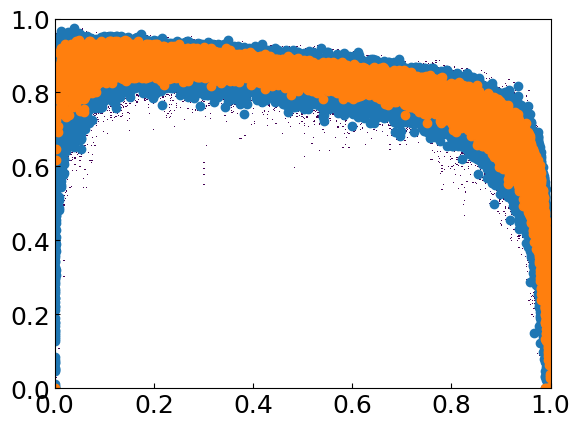

In [46]:
from scipy.stats import binned_statistic_2d
sts = binned_statistic_2d(x=mean_xh, y=r2, values=None, statistic='count', bins=[400, 400])
Nsampl, binx, biny = sts[0], sts[1], sts[2]
mid_x = 0.5*(binx[1:]+binx[:-1])
mid_y = 0.5*(biny[1:]+biny[:-1])

print(mid_x.shape, mid_y.shape)

sort_index = np.argsort(Nsampl.reshape(-1))[::-1]

data = Nsampl.reshape(-1)[sort_index]
bin_xy = np.array(np.meshgrid(mid_y, mid_x))
bin_xy = bin_xy.reshape(2, -1)[:, sort_index]
plt.pcolormesh(mid_x, mid_y, Nsampl.T, norm=colors.LogNorm())
    
for lvl in [0.95, 0.68]:
    tot_sum = 0
    for i in range(data.shape[0]):
        tot_sum += data[i]/data.sum()
        if(tot_sum > lvl):
            i_lvl = i
            break

    Nsampl_r2 = binned_statistic_2d(x=mean_xh, y=r2, values=r2, statistic='mean', bins=[400, 400]).statistic
    mean_lvl = np.mean(Nsampl_r2.flatten()[sort_index][:i_lvl])
    
    print(' level %.2f has average R2 = %.3f' %(lvl, mean_lvl))
    
    plt.scatter(bin_xy[1,:i_lvl], bin_xy[0,:i_lvl])
    plt.ylim(0,1)

(0.0, 1.0)

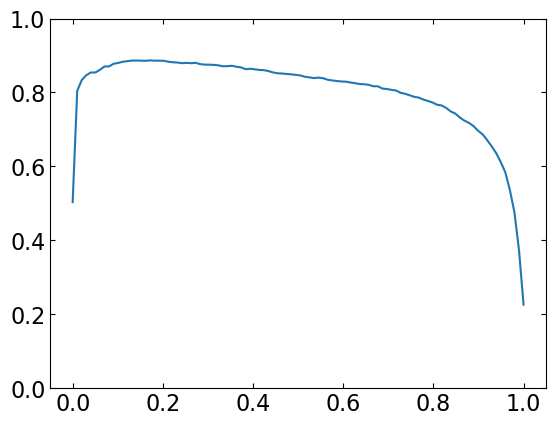

In [20]:
from scipy.stats import binned_statistic_2d

N_r2 = binned_statistic_2d(x=mean_xh, y=r2, values=r2, statistic='mean', bins=[100, 1]).statistic
plt.plot(np.linspace(0, 1, 100), N_r2.flatten())
plt.ylim(0,1)

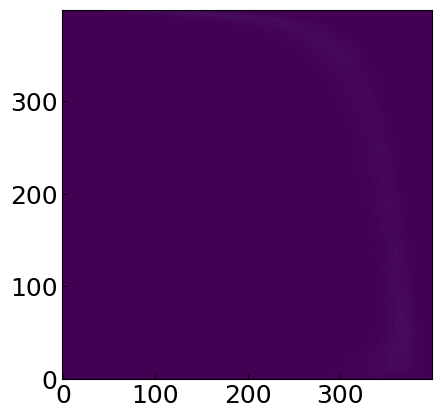

In [45]:
from scipy.stats import binned_statistic_2d

N_r2 = binned_statistic_2d(x=mean_xh, y=r2, values=r2, statistic='sum', bins=[400, 400]).statistic
N_count = binned_statistic_2d(x=mean_xh, y=r2, values=r2, statistic='count', bins=[400, 400]).statistic
N_r2 = np.nan_to_num(Nsampl_r2, nan=0.0)
plt.imshow(N_count, origin='lower')

In [56]:
bin_xH = np.linspace(0, 1, 10)
bin_r2 = np.linspace(0, 1, 10)

N_count = binned_statistic_2d(x=mean_xh, y=r2, values=None, statistic='count', bins=[bin_xH, bin_r2]).statistic/N_count.max()

idx_xh = np.digitize(x=mean_xh, bins=bin_xH, right=True)-1
idx_r2 = np.digitize(x=r2, bins=bin_r2, right=True)-1

weight = np.array([N_count[i, j] for i, j in zip(idx_xh, idx_r2)])

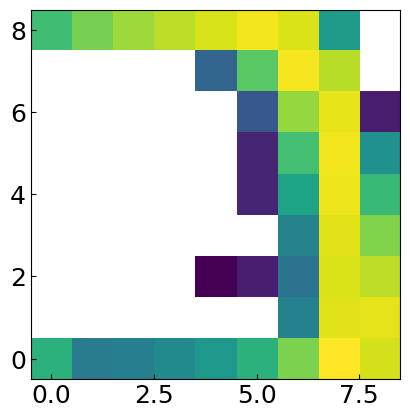

In [57]:
plt.imshow(N_count, origin='lower', norm='log')

In [58]:
np.average(a=r2, weights=weight)

0.7792171958242275

## Visulation of EOS simulation

to consider trying the network on the EOS simulation from Andrei and Munoz

In [4]:
path = './eos_model/'

eos_test1 = np.load(path+'preddT2_fromdT4pca_test1_eos16.npy', mmap_mode='r')
eos_test21 = np.load(path+'preddT2_fromdT4pca_test2.1_eos16.npy', mmap_mode='r')
eos_test32 = np.load(path+'preddT2_fromdT4pca_test3.2_eos16.npy', mmap_mode='r')

eos_predxH = np.load(path+'predxH_fromdT4pca_eos16.npy', mmap_mode='r')
eos_dT4pca = np.load(path+'dT4pca4_eos16.npy', mmap_mode='r')[...,:eos_predxH.shape[-1]]
eos_dT2 = np.load(path+'dT2_eos16.npy', mmap_mode='r')[...,:eos_predxH.shape[-1]]
eos_maskxH = np.load(path+'xH_eos16.npy', mmap_mode='r')[...,:eos_predxH.shape[-1]]
redshift_eos = np.loadtxt(path+'redshift_EOS16_EoR.txt')[:eos_predxH.shape[-1]]

mean_xH_eos = eos_maskxH.mean(axis=(0,1))

In [5]:
redshift = np.loadtxt('/home/mbianco/Documents/PhD_Sussex/output/ML/dataset/inputs/EOS_2016_lc/redshift_EOS16_EoR.txt')
eos_dT = np.load('/home/mbianco/Documents/PhD_Sussex/output/ML/dataset/inputs/EOS_2016_lc/dT_EOS16_EoR.npy', mmap_mode='r')

## SERENEt scheme on large FOV

calculate overlapping map...


100%|████████████████████████████████████████| 225/225 [00:00<00:00, 254.52it/s]


50625 1024.0 4


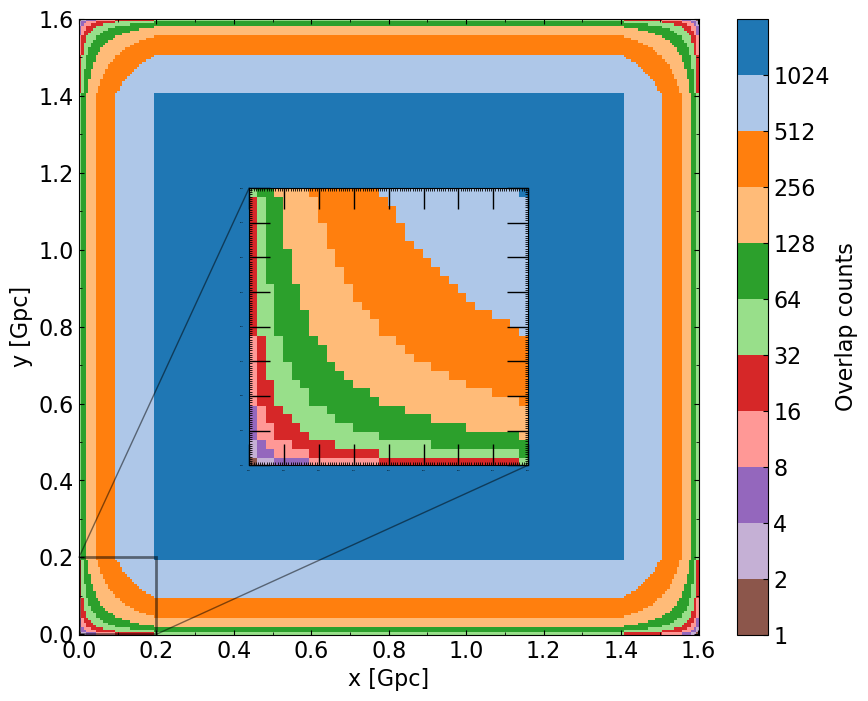

(None, None)

<Figure size 640x480 with 0 Axes>

In [57]:
from matplotlib.colors import ListedColormap, BoundaryNorm

xy = np.linspace(0, 1.6, 1024)
res = 1.6/1024

n_x, n_y = (1024, 1024)
m_x, m_y = (128, 128)
overlp_x, overlp_y = np.array([128, 128])//32

counts_array = np.zeros((n_x, n_y))
count = 0

print('calculate overlapping map...')
for i_x in tqdm(range(0, n_x - m_x + 1, overlp_x)):
    for i_y in range(0, n_y - m_y + 1, overlp_y):
        counts_array[i_x:i_x+m_x,i_y:i_y+m_y] += np.ones((m_x, m_y))
        count += 1
        
print(count, counts_array.max(), step_size_x)
# Define the custom colors for specific values
#colors = list(plt.cm.tab20.colors[:10])+ [plt.cm.Paired.colors[9]]
colors = plt.cm.tab20.colors[:11]
colors = colors[::-1]
boundaries = [1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 2048]

# Create the colormap and norm
cmap = ListedColormap(colors[:len(boundaries) - 1])
norm = BoundaryNorm(boundaries, cmap.N)

fig, ax = plt.subplots(figsize=(10, 8), ncols=1, nrows=1)
zoom_extent = [0., res*128, 0., res*128]

im = ax.pcolormesh(xy, xy, counts_array, cmap=cmap, norm=norm)

# Connect the inset axes with the main axes
axins = ax.inset_axes([0.275, 0.275, 0.45, 0.45])  # [x0, y0, width, height]
axins.pcolormesh(xy, xy, counts_array, cmap=cmap, norm=norm)
axins.set_xlim(zoom_extent[0], zoom_extent[1])
axins.set_ylim(zoom_extent[2], zoom_extent[3])
axins.tick_params(axis='both', direction='in', top=True, right=True, length=15, width=1, labelsize=0)
ax.indicate_inset_zoom(axins, edgecolor="black", linewidth=2)
axins.xaxis.set_major_locator(plt.MultipleLocator(res*16))
axins.xaxis.set_minor_locator(plt.MultipleLocator(res))
axins.yaxis.set_major_locator(plt.MultipleLocator(res*16))
axins.yaxis.set_minor_locator(plt.MultipleLocator(res))

ax.xaxis.set_major_locator(plt.MultipleLocator(0.2))
ax.xaxis.set_minor_locator(plt.MultipleLocator(0.1))
ax.yaxis.set_major_locator(plt.MultipleLocator(0.2))
ax.yaxis.set_minor_locator(plt.MultipleLocator(0.1))


ax.set_xlabel('x [Gpc]'), ax.set_ylabel('y [Gpc]')
cbar = plt.colorbar(im, ax=ax, label='Overlap counts')
# Get the current ticks and remove the last tick
#current_ticks = cbar.get_ticks()
#new_ticks = current_ticks[:-1]  # Exclude the last tick
new_ticks = boundaries[:-1]  # Exclude the last tick
cbar.set_ticks(new_ticks)

#plt.savefig('%sserenet_largefov_coverage.png' %(path_output), bbox_inches='tight')
plt.show(), plt.clf()

In [38]:
list(plt.cm.tab20b.colors)

[(0.2235294117647059, 0.23137254901960785, 0.4745098039215686),
 (0.3215686274509804, 0.32941176470588235, 0.6392156862745098),
 (0.4196078431372549, 0.43137254901960786, 0.8117647058823529),
 (0.611764705882353, 0.6196078431372549, 0.8705882352941177),
 (0.38823529411764707, 0.4745098039215686, 0.2235294117647059),
 (0.5490196078431373, 0.6352941176470588, 0.3215686274509804),
 (0.7098039215686275, 0.8117647058823529, 0.4196078431372549),
 (0.807843137254902, 0.8588235294117647, 0.611764705882353),
 (0.5490196078431373, 0.42745098039215684, 0.19215686274509805),
 (0.7411764705882353, 0.6196078431372549, 0.2235294117647059),
 (0.9058823529411765, 0.7294117647058823, 0.3215686274509804),
 (0.9058823529411765, 0.796078431372549, 0.5803921568627451),
 (0.5176470588235295, 0.23529411764705882, 0.2235294117647059),
 (0.6784313725490196, 0.28627450980392155, 0.2901960784313726),
 (0.8392156862745098, 0.3803921568627451, 0.4196078431372549),
 (0.9058823529411765, 0.5882352941176471, 0.6117647

## Combine plots

In [7]:
eos_stats = np.loadtxt('./eos_model/stats_eos.txt')
redshift_eos = eos_stats[:,0]
r2_eos_test1, r2_eos_test21, r2_eos_test32 = eos_stats[:,1:].T

stats_serenet_i = np.loadtxt('fiducial_model/stats_i232.txt', usecols=(0,1,2,5))
redshift = stats_serenet_i[:,0]
r2_test1, r2_test21, r2_test32 = stats_serenet_i[:,1:].T
mean_xh_eos = xHI.mean(axis=(0,1))

In [10]:
xHI_fit = np.linspace(0.1, 0.9, 9)
p = np.poly1d(np.polyfit(redshift, mean_xh, 12))    # fit a polynomial to make the distribution smoother
redshift_plot = np.array([redshift[np.argmin(abs(p(redshift) - meanHI))] for meanHI in xHI_fit])

xHI_fit_eos = [0.01, 0.05, 0.1, 0.2, 0.3] #np.linspace(0.1, 0.6, 6)
redshift_plot_eos = np.array([redshift[np.argmin(abs(mean_xh_eos - meanHI))] for meanHI in xHI_fit_eos])

(7.1, 8.2)

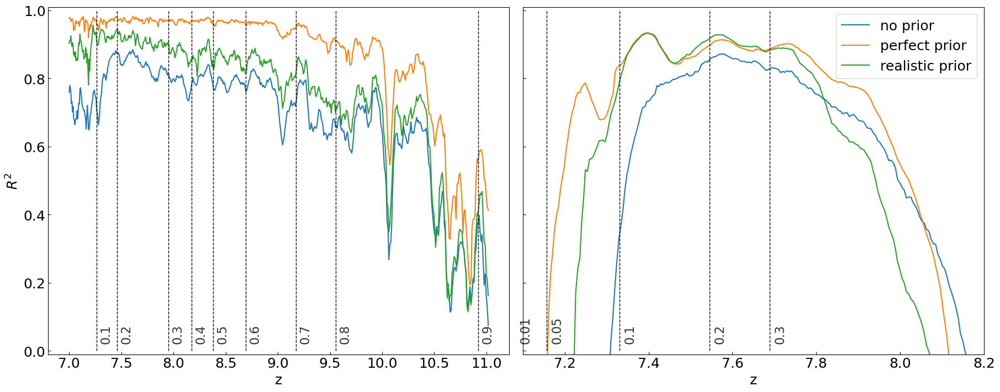

In [11]:
fig1, (ax0, ax1) = plt.subplots(figsize=(18, 7), nrows=1, ncols=2, constrained_layout=True)
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['font.size'] = 18
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.right'] = False

ax0.plot(redshift, r2_test1, label='no prior', color='tab:blue')
ax0.plot(redshift, r2_test21, label='perfect prior', color='tab:orange')
ax0.plot(redshift, r2_test32, label='realistic prior', color='tab:green')
ax0.vlines(redshift_plot, ymin=0, ymax=1, color='black', ls='--', lw=1)
for iplot in range(redshift_plot.size):
    ax0.text(redshift_plot[iplot]+0.03, 0.03, round(xHI_fit[iplot], 1), rotation=90, size=16, alpha=0.8)

ax1.plot(redshift_eos, r2_eos_test1, label='no prior', color='tab:blue')
ax1.plot(redshift_eos, r2_eos_test21, label='perfect prior', color='tab:orange')
ax1.plot(redshift_eos, r2_eos_test32, label='realistic prior', color='tab:green')
ax1.legend(loc=1)
ax1.vlines(redshift_plot_eos, ymin=0, ymax=1, color='black', ls='--', lw=1)
for iplot in range(redshift_plot_eos.size):
    ax1.text(redshift_plot_eos[iplot]+0.01, 0.03, round(xHI_fit_eos[iplot], 2), rotation=90, size=16, alpha=0.8)



for ax in [ax0, ax1]:
    ax.set_xlabel('z'), ax.set_ylabel(r'$R^2$')
    ax.set_ylim(-0.01, 1.01)
    ax.label_outer()

# when all pixel in dT are above non-zero
#ax1.vlines(8.111844490191974, ymin=0, ymax=1, color='black', ls=':', lw=1)
#ax1.vlines(8.5306449547078, ymin=0, ymax=1, color='black', ls='--', lw=1)
ax1.set_xlim(7.1, 8.2)
#plt.savefig('%sstat_fiducial_tests.png' %path_output, bbox_inches='tight')

0.19164855072463766
0.07741123188405796


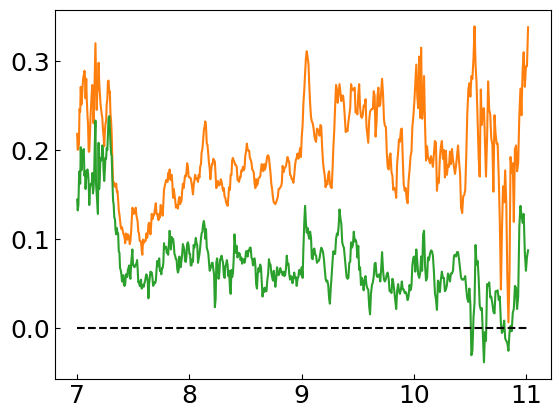

In [12]:
plt.plot(redshift, r2_test21-r2_test1, color='tab:orange')
plt.plot(redshift, r2_test32-r2_test1, color='tab:green')
plt.hlines(y=0, xmin=redshift.min(), xmax=redshift.max(), color='black', ls='--')
#plt.ylim(0, 0.35)

print(np.mean(r2_test21-r2_test1))
print(np.mean(r2_test32-r2_test1))

## EOS visual plot

In [11]:
path = './eos_model/'

eos_test1 = np.load(path+'preddT2_fromdT4pca_test1_eos16.npy', mmap_mode='r')
eos_test21 = np.load(path+'preddT2_fromdT4pca_test2.1_eos16.npy', mmap_mode='r')
eos_test32 = np.load(path+'preddT2_fromdT4pca_test3.2_eos16.npy', mmap_mode='r')

eos_predxH = np.load(path+'predxH_fromdT4pca_eos16.npy', mmap_mode='r')
eos_dT4pca = np.load(path+'dT4pca4_eos16.npy', mmap_mode='r')[...,:eos_predxH.shape[-1]]
eos_dT2 = np.load(path+'dT2_eos16.npy', mmap_mode='r')[...,:eos_predxH.shape[-1]]
eos_maskxH = np.load(path+'xH_eos16.npy', mmap_mode='r')[...,:eos_predxH.shape[-1]]
redshift = np.loadtxt(path+'redshift_EOS16_EoR.txt')[:eos_predxH.shape[-1]]

In [12]:
dT = np.load('/home/mbianco/Documents/PhD_Sussex/output/ML/dataset/inputs/EOS_2016_lc/dT_EOS16_EoR.npy', mmap_mode='r')[...,:eos_predxH.shape[-1]]
xH_eos = np.load('/home/mbianco/Documents/PhD_Sussex/output/ML/dataset/inputs/EOS_2016_lc/xHI_EOS16_EoR.npy', mmap_mode='r')[...,:eos_predxH.shape[-1]]
mean_xH_eos = xH_eos.mean(axis=(0,1)) 

(7.1, 8.2)

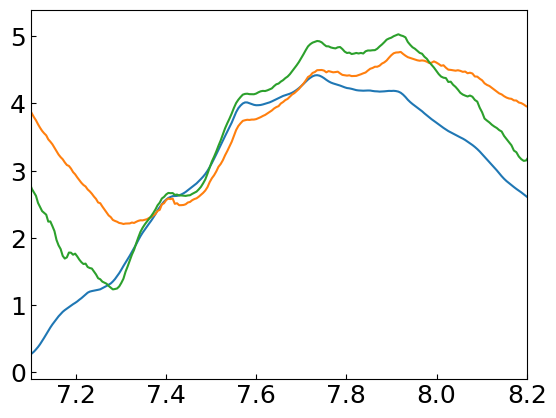

In [13]:
plt.plot(redshift, eos_dT2.std(axis=(0,1)))
plt.plot(redshift, eos_dT4pca.std(axis=(0,1)))
plt.plot(redshift, eos_test32.std(axis=(0,1)))
plt.xlim(7.1, 8.2)

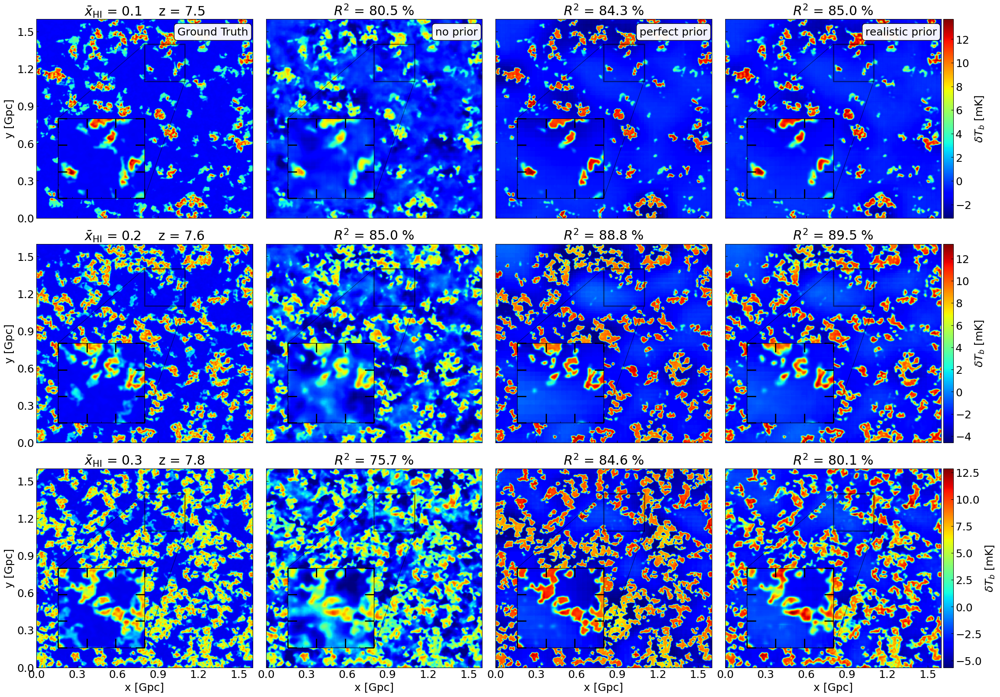

(None, None)

<Figure size 640x480 with 0 Axes>

In [14]:
text = ['Ground Truth', 'no prior', 'perfect prior', 'realistic prior']

zoom = True
#xHI_plot = [0.05, 0.1, 0.2]
xHI_plot = [0.1, 0.2, 0.3]
i_slices = np.array([np.argmin(np.abs(xh-mean_xH_eos)) for xh in xHI_plot])
xy = np.linspace(0, 1.6, 1024)

# Define the extent of the zoomed region
#zoom_extent = [0.900, 1.100, 1.200, 1.400]
#zoom_extent = [0.75, 1.05, 1.1, 1.4]
zoom_extent = [0.8, 1.1, 1.1, 1.4]

#fig, axs = plt.subplots(figsize=(20, 6), ncols=3, nrows=1, constrained_layout=True)
fig, axs = plt.subplots(figsize=(23, 16), ncols=4, nrows=len(i_slices), constrained_layout=True)
for i in range(axs.shape[0]):
    i_slice = i_slices[i]
    # --- PLOT GROUND TRUTH ---
    axs[i,0].set_title(r'$\bar{x}_{\rm HI}$ = %.1f    z = %.1f' %(np.mean(eos_maskxH[...,i_slice]), redshift[i_slice]))
    im = axs[i,0].pcolormesh(xy, xy, eos_dT2[...,i_slice], cmap='jet', vmin=eos_test32[...,i_slice].min(), vmax=eos_test32[...,i_slice].max())
    
    if(zoom):
        # Connect the inset axes with the main axes
        axins = axs[i,0].inset_axes([0.1, 0.1, 0.4, 0.4])  # [x0, y0, width, height]
        axins.pcolormesh(xy, xy, eos_dT2[...,i_slice], cmap='jet', vmin=eos_test32[...,i_slice].min(), vmax=eos_test32[...,i_slice].max())
        axins.set_xlim(zoom_extent[0], zoom_extent[1])
        axins.set_ylim(zoom_extent[2], zoom_extent[3])
        axins.tick_params(axis='both', direction='in', top=True, right=True, length=15, width=2, labelsize=0)
        axs[i,0].indicate_inset_zoom(axins, edgecolor="black", linewidth=2)
        axins.xaxis.set_major_locator(plt.MultipleLocator(0.1))
        axins.xaxis.set_minor_locator(plt.MultipleLocator(0.05))
        axins.yaxis.set_major_locator(plt.MultipleLocator(0.1))
        axins.yaxis.set_minor_locator(plt.MultipleLocator(0.05))
        
    # --- PLOT TEST 1 ---
    r2_test1 = r2_score(eos_dT2[...,i_slice].flatten(), eos_test1[...,i_slice].flatten())
    axs[i,1].set_title(r'$R^2$ = %.1f %%' %(100*r2_test1))
    im = axs[i,1].pcolormesh(xy, xy, eos_test1[...,i_slice], cmap='jet', vmin=eos_test32[...,i_slice].min(), vmax=eos_test32[...,i_slice].max())
    #axs[1].contour(xy, xy, eos_maskxH[...,i_slice], color='grey')
    
    if(zoom):
        # Connect the inset axes with the main axes
        axins = axs[i,1].inset_axes([0.1, 0.1, 0.4, 0.4])  # [x0, y0, width, height]
        axins.pcolormesh(xy, xy, eos_test1[...,i_slice], cmap='jet', vmin=eos_test32[...,i_slice].min(), vmax=eos_test32[...,i_slice].max())
        axins.set_xlim(zoom_extent[0], zoom_extent[1])
        axins.set_ylim(zoom_extent[2], zoom_extent[3])
        axins.tick_params(axis='both', direction='in', top=True, right=True, length=15, width=2, labelsize=0)
        axs[i,1].indicate_inset_zoom(axins, edgecolor="black", linewidth=2)
        axins.xaxis.set_major_locator(plt.MultipleLocator(0.1))
        axins.xaxis.set_minor_locator(plt.MultipleLocator(0.05))
        axins.yaxis.set_major_locator(plt.MultipleLocator(0.1))
        axins.yaxis.set_minor_locator(plt.MultipleLocator(0.05))
        
    # --- PLOT TEST 2.1 ---
    r2_test21 = r2_score(eos_dT2[...,i_slice].flatten(), eos_test21[...,i_slice].flatten())
    axs[i,2].set_title(r'$R^2$ = %.1f %%' %(100*r2_test21))
    im = axs[i,2].pcolormesh(xy, xy, eos_test21[...,i_slice], cmap='jet', vmin=eos_test32[...,i_slice].min(), vmax=eos_test32[...,i_slice].max())
    #axs[1].contour(xy, xy, eos_maskxH[...,i_slice], color='grey')
    
    if(zoom):
        # Connect the inset axes with the main axes
        axins = axs[i,2].inset_axes([0.1, 0.1, 0.4, 0.4])  # [x0, y0, width, height]
        axins.pcolormesh(xy, xy, eos_test21[...,i_slice], cmap='jet', vmin=eos_test32[...,i_slice].min(), vmax=eos_test32[...,i_slice].max())
        axins.set_xlim(zoom_extent[0], zoom_extent[1])
        axins.set_ylim(zoom_extent[2], zoom_extent[3])
        axins.tick_params(axis='both', direction='in', top=True, right=True, length=15, width=2, labelsize=0)
        axs[i,2].indicate_inset_zoom(axins, edgecolor="black", linewidth=2)
        axins.xaxis.set_major_locator(plt.MultipleLocator(0.1))
        axins.xaxis.set_minor_locator(plt.MultipleLocator(0.05))
        axins.yaxis.set_major_locator(plt.MultipleLocator(0.1))
        axins.yaxis.set_minor_locator(plt.MultipleLocator(0.05))
        
    # --- PLOT TEST 3.2 ---
    r2_test32 = r2_score(eos_dT2[...,i_slice].flatten(), eos_test32[...,i_slice].flatten())
    axs[i,3].set_title(r'$R^2$ = %.1f %%' %(100*r2_test32))
    im = axs[i,3].pcolormesh(xy, xy, eos_test32[...,i_slice], cmap='jet', vmin=eos_test32[...,i_slice].min(), vmax=eos_test32[...,i_slice].max())
    #axs[1].contour(xy, xy, eos_maskxH[...,i_slice], color='grey')
    
    if(zoom):
        # Connect the inset axes with the main axes
        axins = axs[i,3].inset_axes([0.1, 0.1, 0.4, 0.4])  # [x0, y0, width, height]
        axins.pcolormesh(xy, xy, eos_test32[...,i_slice], cmap='jet', vmin=eos_test32[...,i_slice].min(), vmax=eos_test32[...,i_slice].max())
        axins.set_xlim(zoom_extent[0], zoom_extent[1])
        axins.set_ylim(zoom_extent[2], zoom_extent[3])
        axins.tick_params(axis='both', direction='in', top=True, right=True, length=15, width=2, labelsize=0)
        axs[i,3].indicate_inset_zoom(axins, edgecolor="black", linewidth=2)
        axins.xaxis.set_major_locator(plt.MultipleLocator(0.1))
        axins.xaxis.set_minor_locator(plt.MultipleLocator(0.05))
        axins.yaxis.set_major_locator(plt.MultipleLocator(0.1))
        axins.yaxis.set_minor_locator(plt.MultipleLocator(0.05))
        
    #plt.colorbar(im, ax=axs[2], pad=0.01)
    plt.colorbar(im, ax=axs[i,3], label=r'$\delta T_b$ [mK]', pad=0.01)

for ax in axs.flatten():
    ax.set_xlabel('x [Gpc]'), ax.set_ylabel('y [Gpc]')
    ax.label_outer()
    ax.xaxis.set_major_locator(plt.MultipleLocator(0.3))
    ax.yaxis.set_major_locator(plt.MultipleLocator(0.3))

box = dict(boxstyle='round', fc='white', ec='black', alpha=0.95)
for j, ax in enumerate(axs[0,:]):
    ax.text(0.98, 0.92, text[j], transform=ax.transAxes, ha='right', bbox=box, fontsize=18)

#plt.savefig('%svisual_comparison_eos.png' %path_output, bbox_inches='tight')
plt.show(), plt.clf()

232805.0 222770.0 223266.0 190711.0


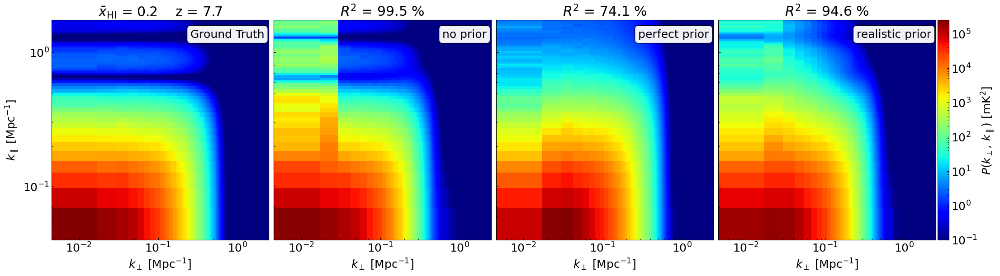

(None, None)

<Figure size 640x480 with 0 Axes>

In [20]:
from matplotlib import colors
text = ['Ground Truth', 'no prior', 'perfect prior', 'realistic prior']

depth_mhz = 20.
z = 7.7
i_slice = np.argmin(np.abs(redshift - z))
box_len = 1600.

kper, kpar = np.loadtxt(path+'kper.txt'), np.loadtxt(path+'kpar.txt')
pk_true = np.loadtxt(path+'pk2D_true.txt', unpack=True)
pk_test1 = np.loadtxt(path+'pk2D_test1.txt', unpack=True)
pk_test21 = np.loadtxt(path+'pk2D_test21.txt', unpack=True)
pk_test32 = np.loadtxt(path+'pk2D_test32.txt', unpack=True)

print(pk_true.max(), pk_test1.max(), pk_test21.max(), pk_test32.max())

fig, axs = plt.subplots(figsize=(22, 6), ncols=4, nrows=1, constrained_layout=True)
# --- PLOT GROUND TRUTH ---
axs[0].set_title(r'$\bar{x}_{\rm HI}$ = %.1f    z = %.1f' %(mean_xH_eos[...,i_slice], redshift[i_slice]))
im = axs[0].pcolormesh(kper, kpar, pk_true, cmap='jet', norm=colors.LogNorm(vmin=1e-1, vmax=2.5e5))

# --- PLOT TEST 1 ---
axs[1].set_title(r'$R^2$ = %.1f %%' %(100*r2_score(pk_true.flatten(), pk_test1.flatten())))
im = axs[1].pcolormesh(kper, kpar, pk_test1, cmap='jet', norm=colors.LogNorm(vmin=1e-1, vmax=2.5e5))
    
# --- PLOT TEST 2.1 ---
axs[2].set_title(r'$R^2$ = %.1f %%' %(100*r2_score(pk_true.flatten(), pk_test21.flatten())))
im = axs[2].pcolormesh(kper, kpar, pk_test21, cmap='jet', norm=colors.LogNorm(vmin=1e-1, vmax=2.5e5))
    
# --- PLOT TEST 3.2 ---
axs[3].set_title(r'$R^2$ = %.1f %%' %(100*r2_score(pk_true.flatten(), pk_test32.flatten())))
im = axs[3].pcolormesh(kper, kpar, pk_test32, cmap='jet', norm=colors.LogNorm(vmin=1e-1, vmax=2.5e5))
    
plt.colorbar(im, ax=axs[3], label=r'$P(k_{\perp},\,k_\parallel)$ [$\rm mK^2$]', pad=0.01)

for j, ax in enumerate(axs.flatten()):
    ax.set_xlabel('$k_\perp$ [Mpc$^{-1}$]'), ax.set_ylabel('$k_\parallel$ [Mpc$^{-1}$]')
    ax.label_outer()
    ax.set_xscale('log'), ax.set_yscale('log')
    #ax.xaxis.set_major_locator(plt.MultipleLocator(0.3))
    #ax.yaxis.set_major_locator(plt.MultipleLocator(0.3))

    box = dict(boxstyle='round', fc='white', ec='black', alpha=0.95)
    ax.text(0.98, 0.92, text[j], transform=ax.transAxes, ha='right', bbox=box, fontsize=18)

#plt.savefig('%spk_comparison_eos.png' %path_output, bbox_inches='tight')
plt.show(), plt.clf()

In [21]:
r2_score(np.log10(pk_true.flatten()), np.log10(pk_test32.flatten()))

-0.30294823760083545

In [32]:
pk_true[0,0]

232805.0

In [ ]:
z_c = 7.6
box_len = 1600.
depth_mhz = 20.

# define wavelengths
kpar_bins = np.linspace(8.5e-2, 1.62, 80)
kper_bins = np.linspace(5e-2, 0.41, 20)

# calculate sub-volume
cut_dT2, box_dims, cut_redshift = t2c.get_lightcone_subvolume(lightcone=eos_dT2, redshifts=redshift, central_z=z_c, 
                                                              depth_mhz=depth_mhz, fov_Mpc=box_len, subtract_mean=False, verbose=False)

ps_true, kper, kpar = t2c.power_spectrum_2d(cut_dT2, kbins=[kper_bins, kpar_bins], box_dims=box_dims, nu_axis=2)

plt.imshow(ps_true)
plt.xscale('log'), plt.yscale('log')
plt.show(), plt.clf()

In [50]:
from sklearn.metrics import matthews_corrcoef, r2_score, mean_squared_error
from skimage.metrics import structural_similarity as ssim

def peak_signal_noise_ratio(image_true, image_test):
    data_range = np.max([image_true.max(), image_test.max()]) - np.min([image_true.min(), image_test.min()])
    err = mean_squared_error(image_true, image_test)
    data_range = float(data_range)  # prevent overflow for small integer types
    return 10 * np.log10((data_range**2) / err)

mean_squared_error(pk_true.flatten(), pk_test32.flatten())

737504.9700359318

In [23]:
mean_squared_error(pk_true.flatten(), pk_test1.flatten())

66103.77186322681

In [24]:
mean_squared_error(pk_true.flatten(), pk_test21.flatten())

3562477.768552933

In [42]:
ssim(pk_true, pk_test32, data_range=1e5 - 1e-1, win_size=3)


0.9989415015333749

In [44]:
ssim(pk_true, pk_test1, data_range=1e5 - 1e-1, win_size=3)


0.9986065689969381

In [52]:
peak_signal_noise_ratio(pk_true, pk_test1)

48.66219655651968